<a href="https://colab.research.google.com/github/mahithamodepalli29/wine-quality-prediction/blob/main/Wine_Quality_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [29]:
df = pd.read_csv("WineQuality.csv")
print(df.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4        5   0  
1      9.8        5   1  
2      9

In [30]:
df = pd.read_csv("WineQuality.csv")
print(df.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  Id  
0      9.4        5   0  
1      9.8        5   1  
2      9

In [31]:
print("Dataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(1143, 13)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB
None

Statistical Summary:


In [32]:
df = df.drop(columns=['Id'])

print("Duplicate Values:")
print(df.duplicated().sum())

df = df.drop_duplicates()

print("\nDataset After Cleaning:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

Duplicate Values:
125

Dataset After Cleaning:
(1018, 12)

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


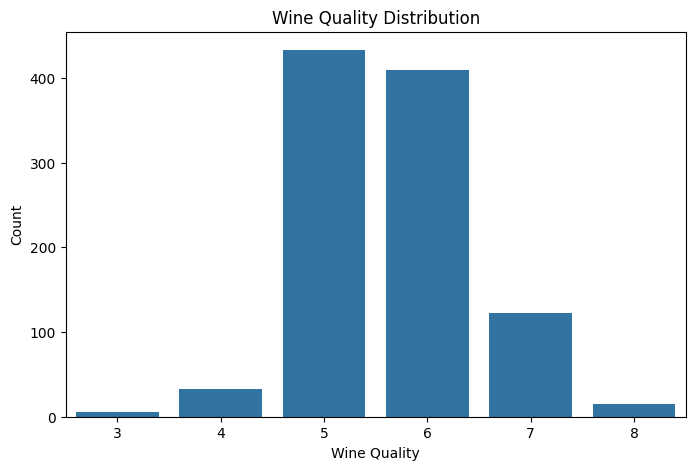

In [33]:
plt.figure(figsize=(8,5))

sns.countplot(x='quality', data=df)

plt.title("Wine Quality Distribution")
plt.xlabel("Wine Quality")
plt.ylabel("Count")

plt.show()

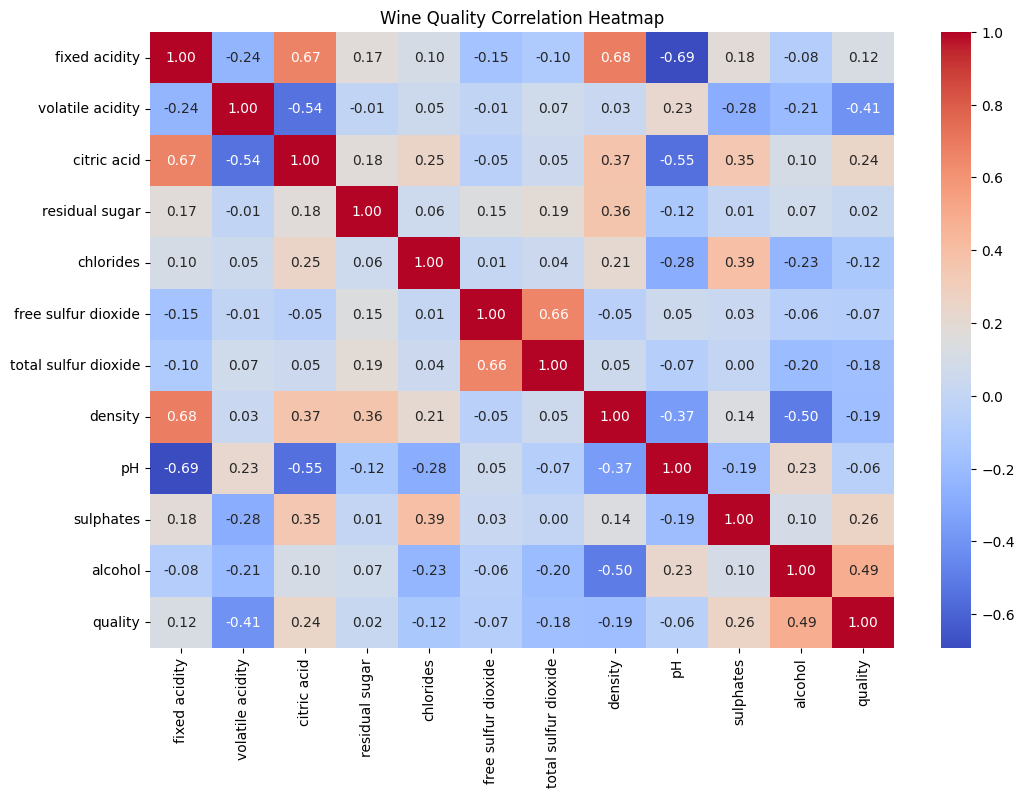

In [34]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(),
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title("Wine Quality Correlation Heatmap")

plt.show()

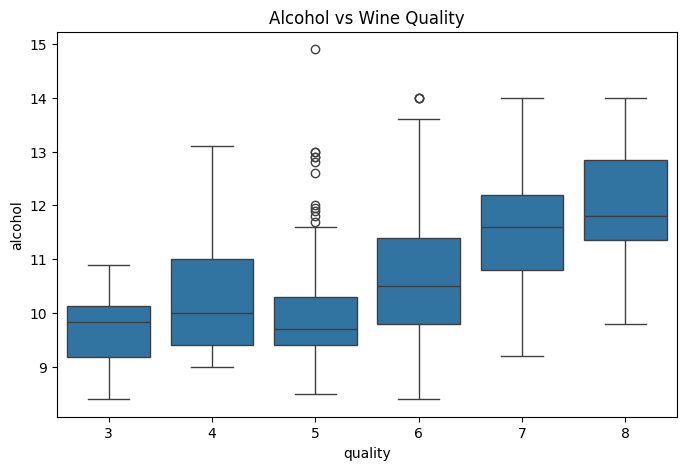

In [35]:
plt.figure(figsize=(8,5))

sns.boxplot(x='quality',
            y='alcohol',
            data=df)

plt.title("Alcohol vs Wine Quality")

plt.show()

In [36]:
X = df.drop('quality', axis=1)

y = df['quality']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
5            7.4              0.66         0.00             1.8      0.075   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
5                 13.0                  40.0   0.9978  3.51       0.56   

   alcohol  
0      9.4  
1      9.8  
2      9.8  
3      9.8  
5    

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (814, 11)
Testing Data: (204, 11)


In [38]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)

print("Linear Regression Completed!")

Linear Regression Completed!


In [39]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Regression Completed!")

Random Forest Regression Completed!


In [40]:
def evaluate_model(name, actual, predicted):

    mae = mean_absolute_error(actual, predicted)

    mse = mean_squared_error(actual, predicted)

    rmse = np.sqrt(mse)

    r2 = r2_score(actual, predicted)

    print("\n", name)

    print("MAE:", mae)

    print("MSE:", mse)

    print("RMSE:", rmse)

    print("R2 Score:", r2)


evaluate_model(
    "Linear Regression",
    y_test,
    lr_predictions
)

evaluate_model(
    "Random Forest Regression",
    y_test,
    rf_predictions
)


 Linear Regression
MAE: 0.5649222522570949
MSE: 0.5263783837300704
RMSE: 0.7255193889415158
R2 Score: 0.3878849074437474

 Random Forest Regression
MAE: 0.5514705882352942
MSE: 0.5060431372549019
RMSE: 0.7113670903653766
R2 Score: 0.41153236650180225


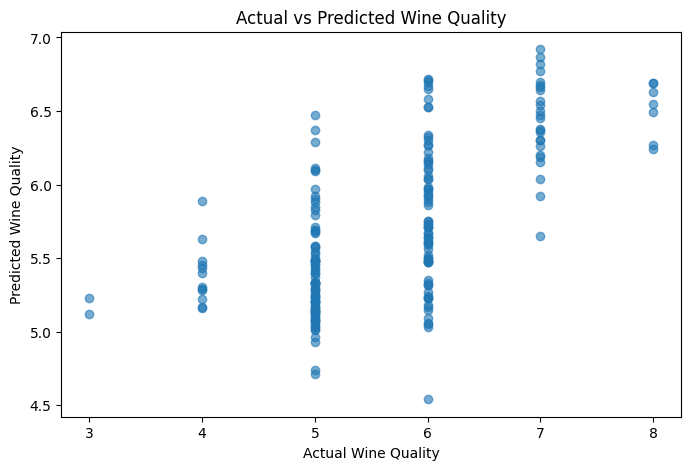

In [41]:
plt.figure(figsize=(8,5))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.6
)

plt.xlabel("Actual Wine Quality")

plt.ylabel("Predicted Wine Quality")

plt.title("Actual vs Predicted Wine Quality")

plt.show()

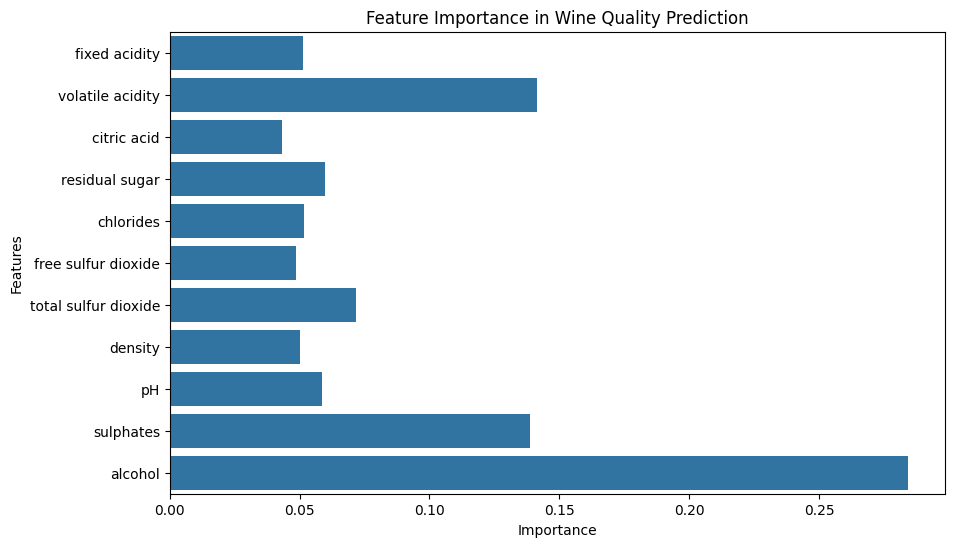

In [42]:
importance = rf_model.feature_importances_

features = X.columns

plt.figure(figsize=(10,6))

sns.barplot(
    x=importance,
    y=features
)

plt.title("Feature Importance in Wine Quality Prediction")

plt.xlabel("Importance")

plt.ylabel("Features")

plt.show()

In [43]:
new_wine = pd.DataFrame([{
    'fixed acidity': 7.4,
    'volatile acidity': 0.50,
    'citric acid': 0.30,
    'residual sugar': 2.0,
    'chlorides': 0.07,
    'free sulfur dioxide': 15,
    'total sulfur dioxide': 40,
    'density': 0.996,
    'pH': 3.3,
    'sulphates': 0.65,
    'alcohol': 10.5
}])

prediction = rf_model.predict(new_wine)

print("Predicted Wine Quality:",
      round(prediction[0], 2))

Predicted Wine Quality: 5.94
